# Assignment 5: numerical near fields of a step-index optical fibre

## 1. Scope and conventions

This project computes the guided near-field modal distributions in cylindrical coordinates $(r,\phi)$, the individual transverse mode patterns, and their coherently superposed output at variable waveguide length $L$ and lens ratio $q=D/f$.

The main source is Ajoy Ghatak, *Optical Electronics*, Chapter 13, §§13.5–13.6, printed pp. 374–380 (PDF pages 385–391 in the supplied scan). Equation numbers below refer to that book. The launch diffraction calculation is derived here as an additional modelling step; it is not attributed to a Chapter 13 equation.

Use the book's time convention, Eq. (13.15):

$$\Psi(r,\phi,z,t)=\psi(r,\phi)e^{i(\omega t-\beta z)}.$$

All computational lengths are in micrometres; $\beta$ is in radians per micrometre. The interface accepts $L$ in millimetres and converts it before evaluating propagation phases. The cladding radius is denoted $r_c$, reserving $b$ for the book's normalized propagation constant.

| Assignment quantity | Value |
|---|---:|
| Vacuum wavelength λ₀ | 0.650 µm |
| Core radius a | 6.25 µm |
| Cladding radius r_c | 62.5 µm |
| Core index n₁ | 1.50 |
| Cladding index n₂ | 1.47 |
| Lens diameter D | 20 mm |
| Initial focal length f | 20 mm |

The fibre is straight, ideal, isotropic and lossless. The core modes use effectively infinite cladding. The weak-guidance parameter $(n_1-n_2)/n_1=0.02$ motivates the scalar LP approximation; this is not a full vector simulation. One fixed linear polarization is launched. Numerical precision within this model is not a claim of equal experimental accuracy.

The assignment does not specify illumination. We assume a centred coherent Gaussian beam at a circular lens, with $1/e$ **field** radius $w_L=2.5\,\mathrm{mm}=D/8$. Its $1/e^2$ intensity radius is the same $w_L$. This relatively underfilled aperture also reduces the angles that carry significant power. The fibre entrance is at the focal plane. $q=D/f$ is varied by changing $f$ at fixed $D$ and keeping that focal-plane placement.

## 2. From the wave equation to the radial eigenproblem

Starting with the scalar approximation of Eq. (13.14),

$$\nabla^2\Psi=\frac{n^2}{c^2}\frac{\partial^2\Psi}{\partial t^2},$$

insert Eq. (13.15). In cylindrical coordinates the transverse equation is Eq. (13.16):

$$\frac{\partial^2\psi}{\partial r^2}+\frac1r\frac{\partial\psi}{\partial r}+\frac1{r^2}\frac{\partial^2\psi}{\partial\phi^2}+[k_0^2n^2(r)-\beta^2]\psi=0,\qquad k_0=\frac{2\pi}{\lambda_0}.$$

Set $\psi=R(r)\Phi(\phi)$ as in Eq. (13.18). Separation and single-valuedness give $\Phi''+\ell^2\Phi=0$, with $\ell=0,1,2,\ldots$ and angular factors $\cos\ell\phi$ or $\sin\ell\phi$. The sine solution at $\ell=0$ vanishes and is not a mode.

Equation (13.21), repeated as (13.26), becomes

$$r^2 R''+rR'+\{[k_0^2n^2(r)-\beta^2]r^2-\ell^2\}R=0.$$

For the step-index profile $n=n_1$ inside $a$ and $n=n_2$ outside, Eqs. (13.30)–(13.32) define

$$U=a\sqrt{k_0^2n_1^2-\beta^2},\quad W=a\sqrt{\beta^2-k_0^2n_2^2},\quad V=\sqrt{U^2+W^2}=k_0a\sqrt{n_1^2-n_2^2}.$$

Guided modes satisfy Eq. (13.22): $n_2k_0<\beta<n_1k_0$. Thus $U,W$ are real and positive. In the core the radial equation is Bessel's equation; outside it is the modified Bessel equation. Reject $Y_\ell$ because it diverges at the origin, and $I_\ell$ because it grows at infinity. Eq. (13.35) gives

$$\psi_{\ell m}=A\begin{cases}J_\ell(Ur/a)/J_\ell(U),&r\le a,\\K_\ell(Wr/a)/K_\ell(W),&r>a,\end{cases}\times\begin{cases}\cos\ell\phi,\\\sin\ell\phi.\end{cases}$$

The ratios already enforce field continuity. Continuity of the radial derivative gives Eq. (13.36):

$$\boxed{\frac{U J_\ell'(U)}{J_\ell(U)}=\frac{W K_\ell'(W)}{K_\ell(W)}}.$$

The numerical residual is the equivalent cross-multiplied expression

$$F_\ell(U)=U J_\ell'(U)-W\frac{K_\ell'(W)}{K_\ell(W)}J_\ell(U),\qquad W=\sqrt{V^2-U^2}.$$

This removes poles from dividing by $J_\ell$. Scaled modified Bessel functions avoid underflow. We bracket each mode between its known cutoff and the relevant zero of $J_\ell$, capped by $V$, and use Brent's numerical root solver. With $j_{\nu,m}$ the $m$th positive zero of $J_\nu$, the brackets are:

- LP(0,1): $0<U<\min(j_{0,1},V)$.
- LP(0,m), $m>1$: $j_{1,m-1}<U<\min(j_{0,m},V)$.
- LP($\ell$,m), $\ell\ge1$: $j_{\ell-1,m}<U<\min(j_{\ell,m},V)$.

Only modes whose cutoff is below $V$ are retained. These cutoffs follow Eqs. (13.42)–(13.44) and Table 13.1. Each root determines

$$\beta=\sqrt{n_1^2k_0^2-U^2/a^2},\qquad n_{\mathrm{eff}}=\beta/k_0,\qquad b=\frac{n_{\mathrm{eff}}^2-n_2^2}{n_1^2-n_2^2}=\frac{W^2}{V^2},$$

where $b$ is Eq. (13.45).

## 3. Mode normalization, counting and interpretation

Implement Eq. (13.23) including the independent angular orientation:

$$\int_0^{2\pi}\int_0^\infty\psi_j^*\psi_k\,r\,dr\,d\phi=\delta_{jk}.$$

The angular squared integral is $2\pi$ for $\ell=0$, and $\pi$ for either cosine or sine when $\ell>0$. Radial integration includes the cladding tail. The normalized scalar fields have units $\mu\mathrm m^{-1}$.

For this fibre, $\mathrm{NA}=\sqrt{n_1^2-n_2^2}=0.298496$ and $V=18.033722>2.405$, so it is multimode. The actual scalar spectrum has **45 LP families**, **84 spatial modes for one polarization**, and **168 modes including both polarizations**. The asymptotic $V^2/2\approx162.61$ is an estimate, not the exact mode count. For $\ell>0$ there are two angular orientations and two polarizations; for $\ell=0$ there is one angular orientation and two polarizations (book p. 375).

A centred circular launch is independent of $\phi$. Hence its angular overlap with every $\ell>0$ mode is zero. The six excited families are LP(0,1) through LP(0,6). All supported families are still computed and available for inspection; unsupported angular content is not artificially added to the output.

## 4. Lens diffraction and the D/f parameter

Let $R_L=D/2$ and write the field immediately before the ideal lens as

$$A_L(\rho)=N_L e^{-\rho^2/w_L^2}\quad (0\le\rho\le R_L),$$

with zero field outside the aperture. Normalize lens-passed scalar power to unity:

$$N_L=\left[\frac{\pi w_L^2}{2}\left(1-e^{-2R_L^2/w_L^2}\right)\right]^{-1/2}.$$

With the $e^{+i\omega t}$ convention, paraxial propagation has kernel $\exp[-ik_0|\mathbf r-\boldsymbol\rho|^2/(2f)]$, while the focusing lens contributes $\exp[+ik_0\rho^2/(2f)]$. At its focal plane, the pupil quadratic terms cancel. Integrating the remaining angular term gives

$$\int_0^{2\pi}e^{i k_0 r\rho\cos\theta/f}\,d\theta=2\pi J_0(k_0r\rho/f).$$

Dropping only an overall phase, the launch at the fibre face is

$$\boxed{E_{\rm in}(r;q)=\frac{2\pi}{\lambda_0 f}e^{-ik_0r^2/(2f)}\int_0^{R_L} A_L(\rho)J_0\left(\frac{k_0r\rho}{f}\right)\rho\,d\rho,\qquad f=D/q.}$$

The code evaluates this Hankel diffraction integral with Gauss–Legendre quadrature. It keeps the weak focal-plane quadratic phase rather than imposing a flat phase. For negligible aperture clipping the independent analytic limit is a Gaussian with

$$w_0=\frac{\lambda_0f}{\pi w_L}=\frac{1.65521}{q}\,\mu\mathrm m.$$

This is also a check on the diffraction integration. It is not a replacement for the numerical integral. At the default $q=1$, $w_0\simeq1.66\,\mu\mathrm m$. At $q=0.1$, $w_0\simeq16.55\,\mu\mathrm m$, wider than the core, so appreciably less power couples into guided modes.

The characteristic Gaussian ray angle is $w_L/f=0.125q$, at most about 0.125 radians. This motivates paraxial focusing for the assumed underfilled pupil, although it remains an approximation. A uniformly filled lens with $D/f=1$ would require a more careful high-angle focusing model. Fresnel reflections and full vector focusing are outside this model.

## 5. Excitation coefficients

The book's complete expansion, Eq. (13.25), contains discrete guided modes and a radiation continuum. Projecting onto normalized guided modes gives

$$\boxed{c_j=\int_0^{2\pi}\int_0^\infty \psi_j^*(r,\phi)E_{\rm in}(r,\phi)r\,dr\,d\phi.}$$

For the centred launch this reduces to $c_{0m}=2\pi\int_0^\infty R_{0m}(r)E_{\rm in}(r)r\,dr$. Numerical quadrature is split at the core boundary and extends sufficiently far into the cladding. The excited amplitudes are complex, and their phases are retained.

With unit lens-passed scalar power, $\eta_j=|c_j|^2$ and $\eta_g=\sum_j|c_j|^2$. The code neither assigns equal weights nor rescales the guided coefficients to sum to unity. $1-\eta_g$ is the unrepresented radiation-component fraction within the ideal scalar projection model; it is not an estimate of all real experimental losses.

**Scope of the output:** we display the guided part of Eq. (13.25). At $L=0$ it is the guided projection of the input, not necessarily the entire focused spot. Radiation/cladding fields near the entrance are not propagated. For small coupling and very short fibres that distinction matters.

## 6. Propagation, field patterns and beating

The guided output follows the discrete part of Eq. (13.25):

$$E_g(r,\phi;L)=\sum_j c_j\psi_j(r,\phi)e^{-i\beta_j L}.$$

For numerical stability and a useful displayed phase reference, remove the common fundamental carrier:

$$\widetilde E_g=e^{i\beta_{01}L}E_g=\sum_j c_j\psi_j e^{-i(\beta_j-\beta_{01})L}.$$

Intensity and all relative modal phases are unchanged. Displayed real and imaginary fields and phase are relative to this carrier. Intensity is $I_g=|\widetilde E_g|^2$, in inverse square micrometres per unit lens-passed scalar power. It is a scalar intensity proxy, not a vector Poynting-flux calculation in watts.

Expanding gives

$$I_g=\sum_j|c_j|^2|\psi_j|^2+2\operatorname{Re}\sum_{j<k}c_jc_k^*\psi_j\psi_k^*e^{-i(\beta_j-\beta_k)L}.$$

The interference terms change with length. Orthogonality makes their transverse integrals vanish, so total guided power stays fixed:

$$\int I_g\,dA=\sum_j|c_j|^2.$$

For two modes, $L_{b,jk}=2\pi/|\beta_j-\beta_k|$. The LP(0,1)/LP(0,2) beat length is about **0.321428 mm**. Multiple beat lengths produce the richer six-mode evolution. Each individual mode's own intensity pattern is independent of $L$.

## 7. Results and checks

The numerical solution gives V = 18.0337 and 45 LP families. For the assumed centred input, six radial modes have nonzero excitation. At D/f = 1, most of the guided power is in LP(0,1), LP(0,2), and LP(0,3). Reducing D/f broadens the focused spot; at D/f = 0.1 the guided fraction is about 0.2953, compared with 0.99999 at D/f = 1.

Changing L changes the relative phases and hence the output pattern. The integrated guided power stays constant. The output is independent of φ because the input is centred and circularly symmetric. Individual nonzero-ℓ modes have angular lobes, as shown in their field plots.

Boundary continuity, mode normalization and power conservation were checked numerically. Refining the quadrature changes the excitation amplitudes by less than 10⁻¹². An independent finite-volume calculation agrees with the six radial eigenvalues to within 8 × 10⁻⁶ in relative U. The complete checks remain in `validate.py`.

The demonstration uses L = 0–5 mm and D/f = 0.10–1.00. The lens-ratio values are calculated in Python in steps of 0.01; changing L evaluates the complex modal sum. Intensity plots use a fixed square-root colour scale to show weaker rings. The radial profiles use a linear scale.

These results use scalar weak guidance, paraxial focusing, and the stated Gaussian launch. They omit radiation propagation, reflections, bending, loss and vector polarization effects. At L = 0 the displayed output is the guided projection of the incident field. The cladding is treated as infinite; the calculated field at its actual outer radius is below 10⁻⁷ of the core peak.

## References

1. PYL209 Assignment 5, supplied `Asg5.pdf`.
2. Ajoy Ghatak, *Optical Electronics*, Chapter 13, §§13.5–13.6, printed pp. 374–380, Eqs. (13.14)–(13.47) and Table 13.1.


## 8. Numerical results
Run from the project directory with the installed Python dependencies. The following cells compute the spectrum, coupling and validation; figures are regenerated by `build_project.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fibre import Simulation
from validate import run_validation
sim = Simulation()
print(f'V = {sim.fibre.V:.6f}; {len(sim.modes)} LP families; {len(sim.active)} excited radial modes.')

V = 18.033722; 45 LP families; 6 excited radial modes.


In [2]:
from IPython.display import display, Markdown, Image
rows = ['| Mode | U | W | n_eff | Power fraction at D/f=1 |', '|---|---:|---:|---:|---:|']
c = sim.coefficients(1.0)
for m, cj in zip(sim.active, c):
    rows.append(f'| {m.label} | {m.u:.8f} | {m.w:.8f} | {m.neff:.9f} | {abs(cj)**2:.8f} |')
display(Markdown('\n'.join(rows)))

| Mode | U | W | n_eff | Power fraction at D/f=1 |
|---|---:|---:|---:|---:|
| LP(0,1) | 2.27814539 | 17.88924813 | 1.499525958 | 0.38924643 |
| LP(0,2) | 5.22603234 | 17.25988792 | 1.497503731 | 0.41605636 |
| LP(0,3) | 8.18270143 | 16.07042446 | 1.493872730 | 0.16192352 |
| LP(0,4) | 11.12652315 | 14.19209736 | 1.488651181 | 0.02978650 |
| LP(0,5) | 14.03851847 | 11.31967951 | 1.481892541 | 0.00283046 |
| LP(0,6) | 16.86218832 | 6.39388380 | 1.473804761 | 0.00015004 |

In [3]:
report = run_validation(sim)
assert report['all_passed'], report
print('Numerical checks passed.')

Numerical checks passed.


### Modal fields in (r, φ), patterns and radial profiles

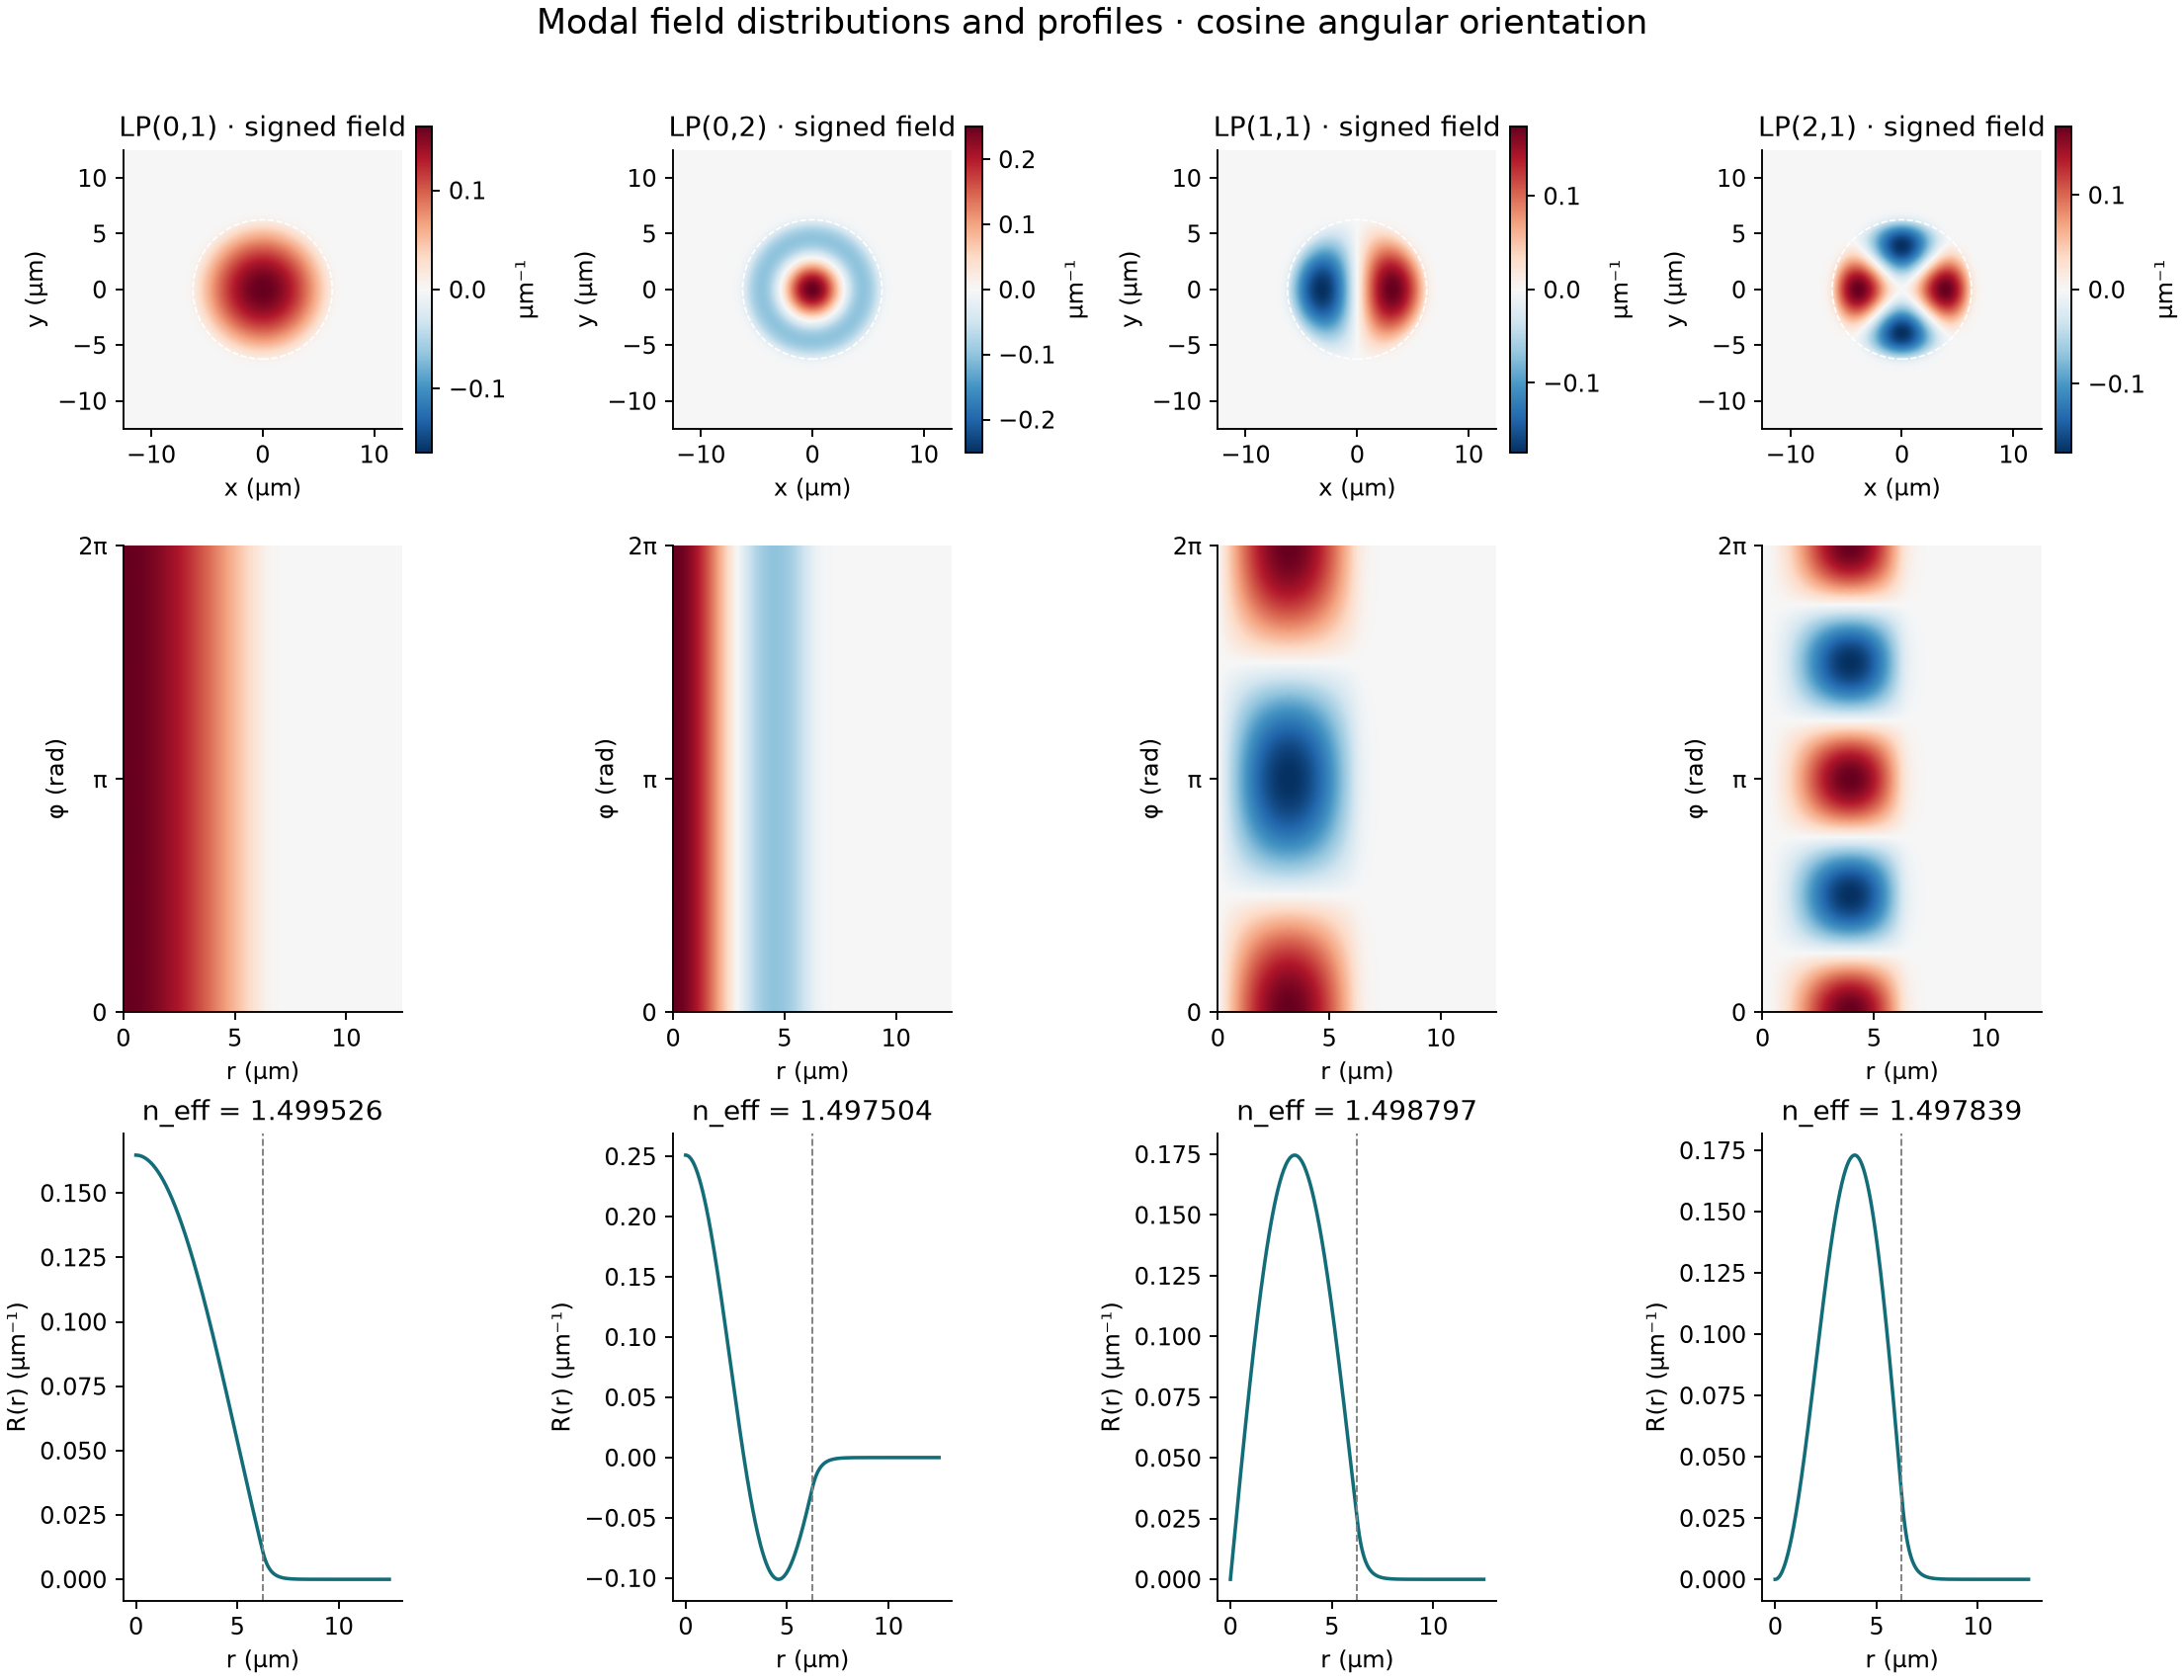

In [4]:
display(Image(filename='results/modal_distributions.png'))

### Variable waveguide length L

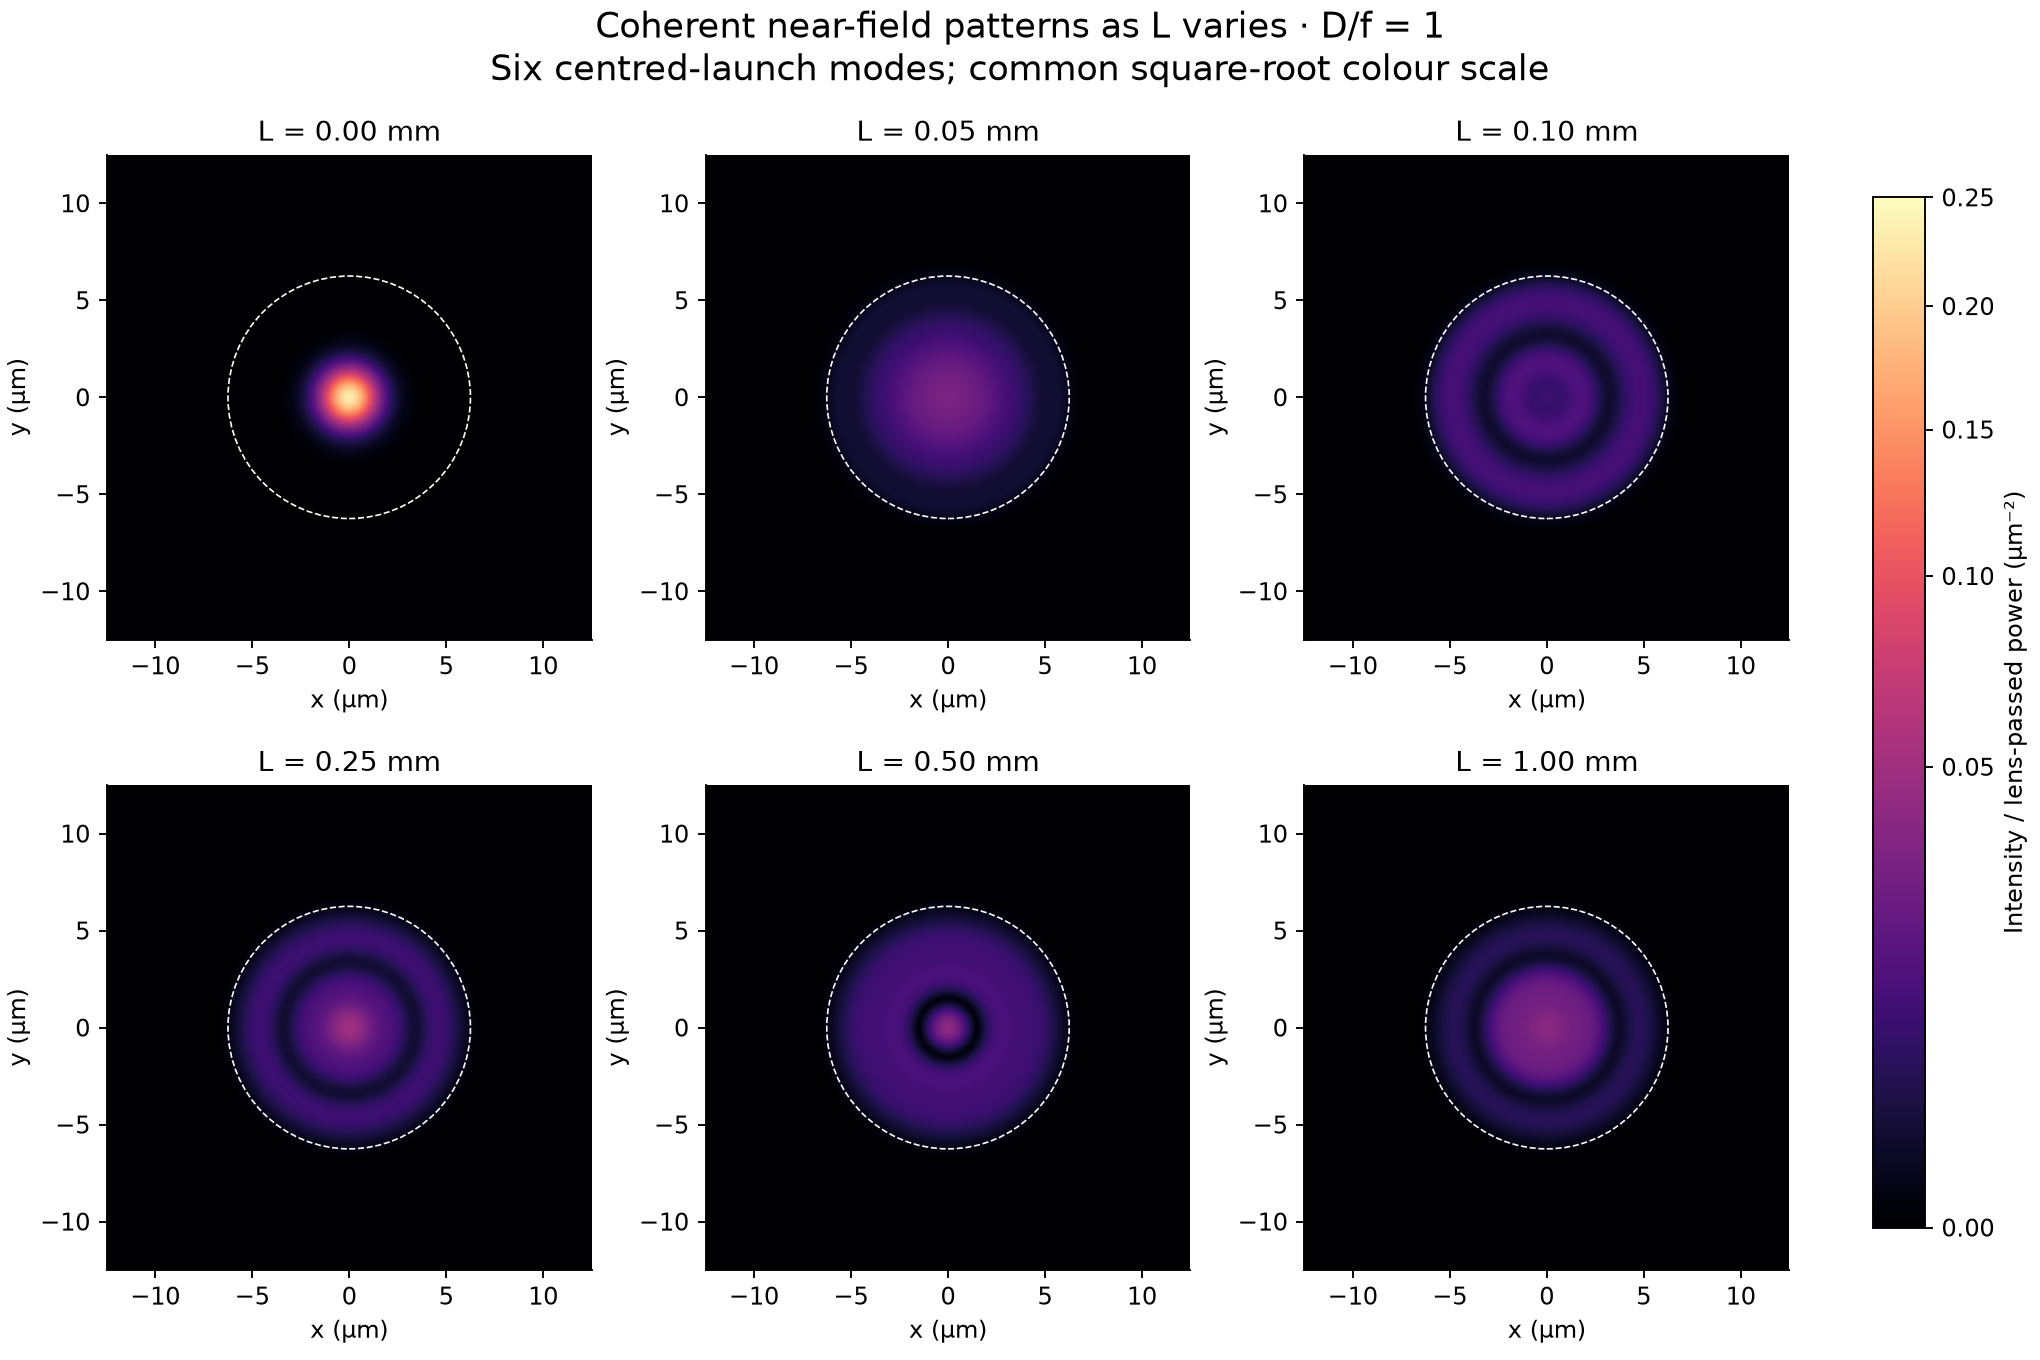

In [5]:
display(Image(filename='results/length_patterns.png'))

### Variable lens ratio D/f

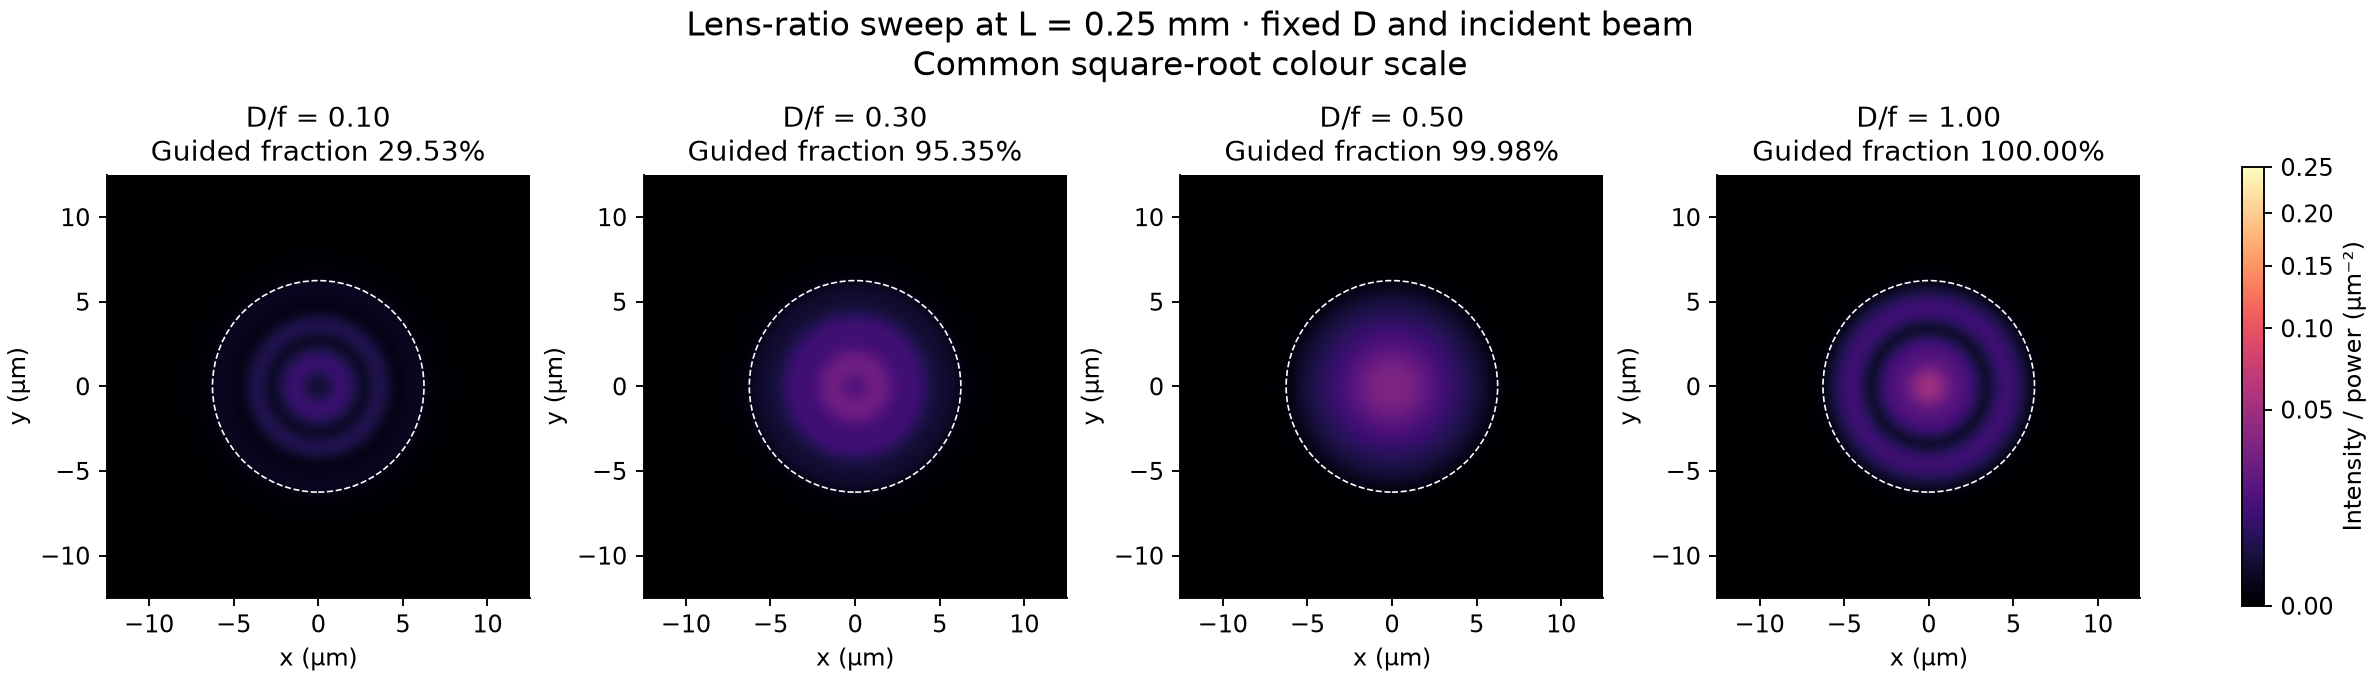

In [6]:
display(Image(filename='results/lens_patterns.png'))

## 9. Demonstration
Open `Fibre_Demo.html` and vary L and D/f. The two views show the summed output and individual modal fields.